# Laboratoire de programmation mathématique 4 :<br/> Que ça bouge! <span style="color:silver">(équations différentielles ordinaires)</span>

Où nous verrons comment les choses évoluent dans le temps, en utilisant des équations différentielles (ordinaires).

## Maîtriser la croissance exponentielle

### Un peu de maths : équations différentielles ordinaires (EDO)

Les EDO sont des équations impliquant une fonction inconnue (que nous voulons trouver) et ses dérivées. Elles sont essentielles pour modéliser des systèmes dynamiques en physique, ingénierie, biologie, économie et dans de nombreux autres domaines. La forme générale d'une EDO du premier ordre est :

$$y'(t) = f(t, y(t))$$
où :
- $y(t)$ est la fonction inconnue de la variable indépendante $t$ ($t$ est généralement le temps)
- $f(t, y)$ est une fonction connue - comme $f(t, y)= y^2 + e^y \sin t$
- Typiquement, on nous donne également une "condition initiale", c'est-à-dire la valeur $y_0:=y(t_0)$ pour un certain $t_0\in\mathbb R$

Par exemple, un modèle simple de croissance exponentielle est :

$$\frac{dy}{dt} = ky$$

où $k$ (une constante) est le taux de croissance. Cela peut décrire :

 - Tu déposes le montant $y_0$ sur un compte bancaire au temps $t_0$. Si le taux d'intérêt est $k$, alors au temps $t$ tu auras $y(t)$ sur ton compte.
 - Tu as un bloc d'uranium (non enrichi), qui se désintègre très lentement par radioactivité (il faut environ $4,5\times 10^9$ ans, soit l'âge de notre planète, pour que la moitié se transforme en d'autres éléments). Au temps $t_0$, la masse totale de l'uranium est $y_0$, au temps $t$ elle est $y(t)$. Dans ce cas, $k$ est négatif et donne le taux de désintégration.
 - Un modèle très naïf de croissance de population.

### Résoudre les EDO numériquement : la méthode d'Euler

Si $dt$ est un nombre très petit, une EDO $dy/dt = f(t,y)$ dit que 
$$y(t+dt)\approx y(t) + f(t, y(t))\,dt$$
(par exemple : $dt$ pourrait être 1 seconde et chaque seconde la banque augmente le montant sur ton compte). En d'autres termes, si  
$$t_n:= t_0 + n\,dt\quad\text{et}\quad y_n = y(t_n)$$
alors 
$$y_{n+1}\approx y_n + f(t_n, y_n)\,dt.$$
La _méthode d'Euler_ calcule les $y_n$ de façon itérative en utilisant la formule (approximative)
$$y_{n+1} = y_n + f(t_n, y_n)\,dt$$
(et interpole les $y_n$ linéairement, si nécessaire).

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

 - Implémente une fonction `euler_method(f, y_0, t_0, t_max, dt)` qui renvoie
 $$\bigl([y_0, y_1,\dots, y_N],\ [t_0, t_1,\dots, t_N]\bigr)$$ calculé par la méthode d'Euler. L'indice maximal $N$ est déterminé par $t_N\leq t_{max} < t_{N+1}$.
 - Trace (sur le même graphique) les résultats de la méthode d'Euler pour la fonction $f(t, y) = y$ avec la condition initiale $y_0=0.1$, une fois avec $dt = 0.1$ et une fois avec $dt=0.01$. Pour les autres paramètres, utilise $t_0=0$, $t_{max}=4$. Trace également la vraie solution de l'équation différentielle $y'=y$ avec $y(0)=0.1$, à savoir $y(t)=0.1\times \exp t$.
 - Pour le prochain graphique, utilise la fonction $f(t, y) = y - y^2$. C'est un modèle légèrement moins naïf de croissance de population, incluant un effet négatif de la surpopulation. Trace les résultats de la méthode d'Euler (sur le même graphique) pour les trois conditions initiales $y_0=0.1$, $y_0=0.4$, $y_0=0.7$, chaque fois avec les paramètres $t_0=0$, $t_{max}=10$, $dt=0.01$. Observe comment $y(t)$ converge vers 1 quand $t$ augmente.
 - Enfin, répète le problème précédent avec $f(t, y) = (1 + \sin(2t))\, y - y^2$ - dans ce modèle, le taux de croissance dépend du temps
</div>

In [1]:
import matplotlib.pyplot as plt
import numpy as np

def euler_method(f, y_0, t_0, t_max, dt):

    N = int((t_max-t_0)/dt)+1

    t_values = np.zeros(N)
    y_values = np.zeros((N,4))

    t_values[0] = t_0
    y_values[0] = y_0

    for i in range(N-1):

        y_values[i+1] = y_values[i] + f(t_values[i], y_values[i])*dt
        t_values[i+1] = t_values[i] + dt

    return t_values, y_values
    

## Se déplacer autour du Soleil

### L'EDO décrivant le mouvement d'une planète (lois de Newton)

Dans de nombreuses situations, nous avons une EDO
$$y'(t) = f(t, y(t))$$
où $y(t)$ n'est pas un seul nombre mais un vecteur (et $f(t, y(t))$ aussi). Décrivons un cas particulier, donnant le mouvement d'une planète autour du Soleil.


<img src="attachment:b74f6748-2fd2-4761-940f-68f109f85634.png" width="750">


Comme tu le sais peut-être, le Soleil attire la planète avec une force $G M m / r^2$, où $G$ est la constante gravitationnelle, $M$ est la masse du Soleil, $m$ celle de la planète, et $r$ la distance entre le Soleil et la planète. Cette force fait accélérer la planète vers le Soleil, avec l'accélération $G M / r^2$. Pour simplifier la notation, nous supposerons que $GM=1$.

Traduisons cela en une EDO $y'(t) = f(t, y(t))$.
Dans ce cas, le vecteur $y(t)$ a quatre composantes : deux d'entre elles, $x_1(t)$ et $x_2(t)$, donnent la position de la planète au temps $t$ (la planète se déplace dans un plan, les coordonnée du Soleil sont $(0,0)$) et les deux autres, $v_1(t)$ et $v_2(t)$, sont les composantes de la vitesse de la planète. L'EDO est
$$x_1'(t) = v_1(t)$$
$$x_2'(t) = v_2(t)$$
$$v_1'(t) = - \frac{x_1(t)}{(x_1(t)^2 + x_2(t)^2)^{3/2}}$$
$$v_2'(t) = - \frac{x_2(t)}{(x_1(t)^2 + x_2(t)^2)^{3/2}}$$
où les deux dernières équations sont les composantes de l'accélération. Les deux premières équations disent simplement que $(v_1, v_2)$ est la vitesse de la planète.


<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

 - Écris une fonction Python `f_Sun(t, y)` qui suppose que l'entrée $y$ est un tableau numpy avec 4 composantes $(x_1(t), x_2(t), v_1(t), v_2(t))$, et renvoie le tableau contenant les membres de droite des 4 équations ci-dessus.
 - En utilisant ta fonction `euler_method`, calcule $[y_0, y_1,\dots,y_N]$ avec la condition initiale
 $$y_0 := y(0) = \bigl(x_1(0)=1,\, x_2(0)=0,\, v_1(0)=0,\, v_2(0)=1.2\bigr).$$
  Utilise les paramètres $t_0=0$, $t_{max}=100$, $dt = 0.01$.
 - Extrais de la liste $[y_0, y_1,\dots,y_N]$ (contenant des tableaux de longueur 4) deux listes, contenant les valeurs de $x_1$ et $x_2$ au fil du temps.
 - Trace la trajectoire de la planète ; utilise la commande `plt.axis('equal')` pour garder les proportions correctes (just avant `plt.show()`)
</div>

**Un piège possible en python/numpy :**
Ta fonction `euler_method(f,y_0, ...)` devrait fonctionner sans problème même quand `y_0` est un tableau numpy. Tu devrais cependant utiliser `y_n = y_n + f(t, y_n) * dt` pour mettre à jour le tableau (ou quelque chose d'équivalent), et non `y_n += f(t, y_n) * dt` - ce dernier change `y_n` "sur place", alors que le premier crée un nouveau tableau.


In [3]:
def f_Sun(t, y):

    x1 = y[0]
    x2 = y[1]
    v1 = y[2]
    v2 = y[3]

    dx1 = v1
    dx2 = v2
    dv1 = -x1 / (x1**2+x2**2)**1.5
    dv2 = -x2 / (x2**2 + x1**2)**1.5

    return np.array([dx1, dx2, dv1, dv2])

In [4]:
t_0 = 0
t_max =100
dt = 0.01
y_0 = np.array((1, 0, 0, 1.2))

t_values, y_values = euler_method(f_Sun, y_0, t_0, t_max, dt)

In [5]:
x1_liste = y_values[:, 0]
x2_liste = y_values[:, 1]

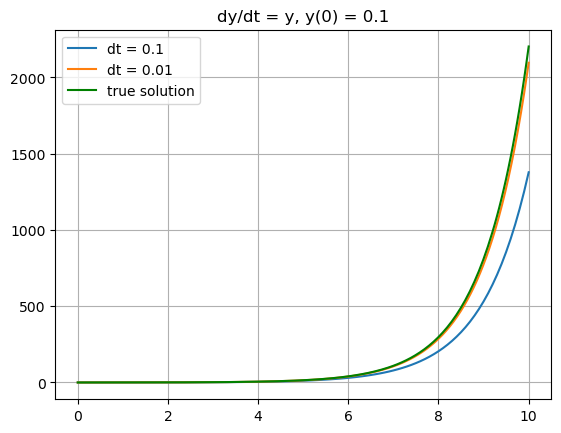

In [6]:
def f1(t, y):
    return y

t_0 = 0
t_max = 10
y_0 = np.array([0.1])

t_val_1, y_val_1 = euler_method(f1, y_0, t_0, t_max, 0.1)
t_val_2, y_val_2 = euler_method(f1, y_0, t_0, t_max, 0.01)

t_exact = np.linspace(t_0, t_max, 200)
y_exact = 0.1 * np.exp(t_exact)

plt.plot(t_val_1, y_val_1[:, 0], label='dt = 0.1')
plt.plot(t_val_2, y_val_2[:, 0], label='dt = 0.01')
plt.plot(t_exact, y_exact, label='true solution', color='green')
plt.title('dy/dt = y, y(0) = 0.1')
plt.legend()
plt.grid()
plt.show()

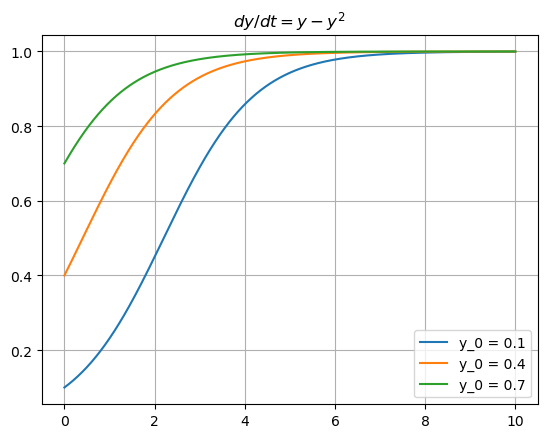

In [7]:
def f2(t, y):
    return y - y**2

t_0 = 0
t_max = 10
dt = 0.01

y_0_a = np.array([0.1])
y_0_b = np.array([0.4])
y_0_c = np.array([0.7])

t_val, y_val_a = euler_method(f2, y_0_a, t_0, t_max, dt)
_, y_val_b = euler_method(f2, y_0_b, t_0, t_max, dt)
_, y_val_c = euler_method(f2, y_0_c, t_0, t_max, dt)

plt.plot(t_val, y_val_a[:, 0], label='y_0 = 0.1')
plt.plot(t_val, y_val_b[:, 0], label='y_0 = 0.4')
plt.plot(t_val, y_val_c[:, 0], label='y_0 = 0.7')
plt.title(r'$dy/dt = y - y^2$')
plt.legend()
plt.grid()
plt.show()

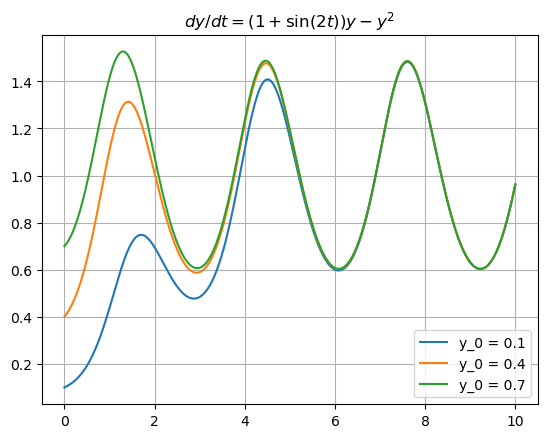

In [8]:
def f3(t, y):
    return (1 + np.sin(2*t))*y - y**2

t_0 = 0
t_max = 10
dt = 0.01

t_val, y_val_a3 = euler_method(f3, np.array([0.1]), t_0, t_max, dt)
_, y_val_b3 = euler_method(f3, np.array([0.4]), t_0, t_max, dt)
_, y_val_c3 = euler_method(f3, np.array([0.7]), t_0, t_max, dt)

plt.plot(t_val, y_val_a3[:, 0], label='y_0 = 0.1')
plt.plot(t_val, y_val_b3[:, 0], label='y_0 = 0.4')
plt.plot(t_val, y_val_c3[:, 0], label='y_0 = 0.7')
plt.title(r'$dy/dt = (1 + \sin(2t))y - y^2$')
plt.legend()
plt.grid()
plt.show()

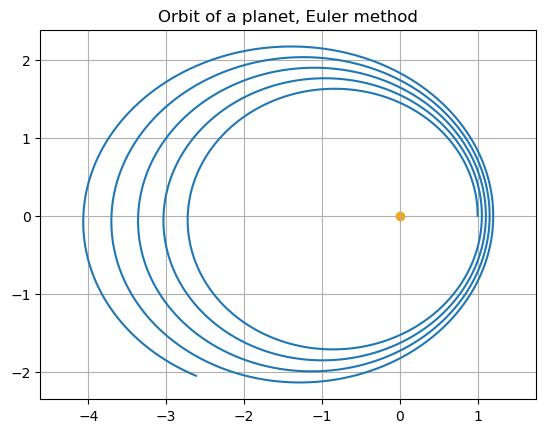

In [9]:
plt.plot(x1_liste, x2_liste)
plt.scatter(0,0, color ='orange')
plt.title("Orbit of a planet, Euler method")
plt.grid()
plt.axis('equal')
plt.show()

Tu sais probablement que l'orbite d'une planète est une ellipse avec un foyer au Soleil (l'origine). Si tout s'est bien passé, tu as obtenu une courbe qui ressemble à une ellipse, mais qui s'éloigne en spirale du Soleil. Nous avons besoin d'une solution plus précise.

### Améliorer la méthode d'Euler

Comment obtenir une solution plus précise ? Une option est de diminuer $dt$, mais cela ralentit le calcul. Une meilleure option est d'améliorer la méthode d'Euler. Elle était basée sur l'égalité approximative
$$y_{n+1}\approx y_n + f(t_n, y_n)\,dt.$$
Nous pouvons améliorer cette approximation par la "méthode du point milieu" : l'approximation
$$y_{n+1}\approx y_n + f\bigl((t_n + t_{n+1})/2,\; (y_n + y_{n+1})/2\bigr)\,dt$$
est beaucoup plus précise. Un inconvénient est que $y_{n+1}$ est aussi dans le membre de droite, et nous ne le connaissons pas, mais nous le remplaçons simplement par la valeur donnée par la méthode d'Euler. La méthode du point milieu devient alors
$$y_{n+1} = y_n + f\bigl((t_n + t_{n+1})/2,\; y_n + f(t_n, y_n)\,dt/2\bigr)\,dt$$

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Implémente la méthode du point milieu et essaie-la pour le mouvement de la planète. (Tu peux utiliser numba si tu veux accélérer le calcul, mais ce n'est pas du tout nécessaire pour notre problème simple.)
</div>

> L'orbite d'une planète typique est très proche d'un cercle. La position initiale est choisie ici pour obtenir une ellipse plus prononcée - de telles trajectoires sont plus typiques pour des astéroïdes. 


In [10]:
### ÉCRIS ICI

def methode_point_milieu(y_0, t_0, t_n, f, dt):

    N = int((t_n - t_0)/dt+1)

    t_values = np.zeros(N)
    y_values = np.zeros((N, 4))

    t_values[0] = t_0
    y_values[0] = y_0

    for i in range(N-1):

        t_milieu = t_values[i] +dt/2
        y_milieu = y_values[i] + f(t_values[i], y_values[i])*dt/2

        t_values[i+1] = t_values[i] + dt
        y_values[i+1] = y_values[i] + f(t_milieu, y_milieu)*dt

    return t_values, y_values

In [11]:
t_0 = 0
t_n = 100
dt = 0.01
y_0 = np.array((1, 0, 0, 1.2))

t_values, y_values = methode_point_milieu(y_0, t_0, t_n, f_Sun, dt)

In [12]:
x1_liste = y_values[:, 0]
x2_liste = y_values[:, 1]

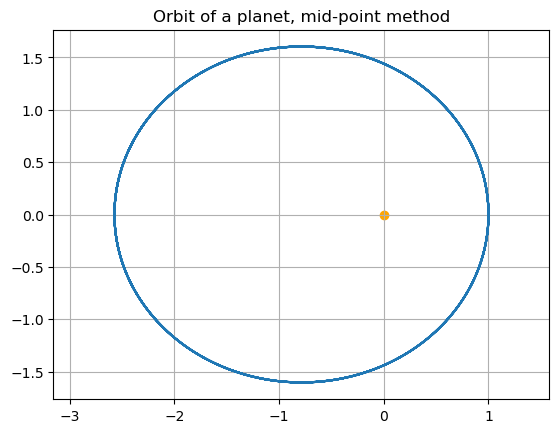

In [13]:
plt.plot(x1_liste, x2_liste)
plt.scatter(0,0, color ='orange')
plt.title("Orbit of a planet, mid-point method")
plt.grid()
plt.axis('equal')
plt.show()

Il existe des méthodes encore plus sophistiquées et précises (la plus célèbre est la méthode de Runge-Kutta d'ordre 4). Au lieu de les étudier, utilisons la fonction `solve_ivp` de la bibliothèque `scipy` qui les implémente ("ivp" signifie "problème à valeur initiale"). La fonction est importée via
```python
from scipy.integrate import solve_ivp
```
> scipy est une immense bibliothèque - si tu as besoin d'un algorithme numérique, il est très probable qu'il soit déjà dans scipy

Nous l'exécutons ensuite comme
```python
solution = solve_ivp(f, (t_0, t_max), y_0, atol=1e-9, rtol=1e-9)
```
> Les options `atol=1e-9, rtol=1e-9` (tolérance absolue, tolérance relative) augmentent simplement la précision - tu peux les omettre et voir ce qui se passe (ou les remplacer par les nombres que tu veux ; la valeur par défaut est `0.001`). Le mouvement céleste est assez sensible aux erreurs numériques, il est donc judicieux d'augmenter la précision.

Alors `solution.t` est un tableau numpy des temps (il est de taille `N`, où la valeur de `N` a été choisie par `solve_ivp` de manière appropriée) et `solution.y` contient les valeurs de `y` à ces temps - plus précisément, c'est un tableau à 2 dimensions de taille `(n, N)`, où `n` est la taille (dimension) de `y_0`

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**
Utilise `solve_ivp` pour trouver la trajectoire d'une planète, avec les mêmes conditions initiales que ci-dessus, et trace-la.
</div>


>  tu peux obtenir `x_1` et `x_2` simplement par `x_1 = solution.y[0]` et `x_2 = solution.y[1]` - les tableaux numpy sont vraiment pratiques.


In [14]:
from scipy.integrate import solve_ivp

t_max = 50
t_eval = np.linspace(t_0, t_max, 1000)
solution = solve_ivp(f_Sun, (t_0, t_max), y_0, atol=1e-9, rtol=1e-9)

x_1 = solution.y[0]
x_2 = solution.y[1]

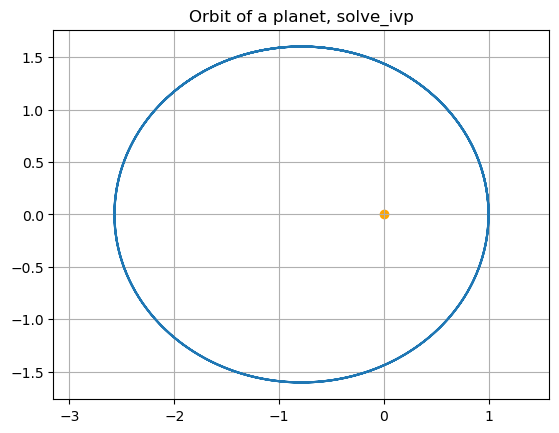

In [15]:
plt.plot(x_1, x_2)
plt.axis('equal')
plt.scatter(0,0, color = 'orange')
plt.title('Orbit of a planet, solve_ivp')
plt.grid()
plt.show()

### Jupiter dans Jupyter

Outre le Soleil, Jupiter est une force majeure dans le système solaire. Sa masse est d'environ 1/1000 de la masse du Soleil, ce qui peut sembler négligeable, mais comme elle tourne autour du Soleil, elle influence pas mal les corps plus petits et peut provoquer leurs collisions ou les éjecter hors du système solaire. Simulons comment elle agit sur des planètes (hypothétiques).
> En réalité, il n'y a pas de planète aussi proche de Jupiter que celles que nous allons simuler. D'un autre côté, nous ne résoudrons les équations que pour une durée de 80 années joviennes, nous devons donc nous rapprocher pour voir une forte influence. La ceinture d'astéroïdes, cependant, se trouve à peu près là où sont nos planètes (hypothétiques) à l'intérieur de l'orbite de Jupiter, donc cette simulation n'est pas purement théorique.

Voici ce qui se passe si une planète est attirée à la fois par le Soleil et par Jupiter.


<img src="attachment:dd10bd88-2b83-41d3-9622-deabc235fb82.png" width="750">


L'accélération de la planète est la somme de deux vecteurs. L'un provient du Soleil, et nous l'avons déjà rencontré : ce vecteur pointe vers le Soleil et sa taille est $1/r^2$, où $r$ est la distance de la planète au Soleil. L'autre provient de Jupiter, il pointe vers la position de Jupiter, et sa taille est $\mu/r_J^2$, où $r_J$ est la distance de la planète à Jupiter et $\mu=1/1000$ (le rapport des masses de Jupiter et du Soleil).


<div style="border: 1px solid gold; padding: 5px">


**Exercice :**

 - Dans la cellule ci-dessous, écris une fonction `f_Sun_and_Jupiter(t, y)` qui renvoie le quadruplet `[v1, v2, a1, a2]`, où `v1, v2` sont les composantes de la vitesse de la planète et `a1, a2` sont les composantes de son accélération (sous l'influence combinée du Soleil et de Jupiter). L'entrée `y` est le quadruplet `[x1, x2, v1, v2]`, où `x1, x2` est la position de la planète. Pour obtenir la position de Jupiter au temps `t`, utilise `jupiter_position(t)` - la fonction est déjà implémentée dans la cellule ci-dessous.
 - La variable `planets` contient les `y` initiaux (au temps 0) de 8 planètes. Pour chacune d'entre elles, trouve leur trajectoire pour l'intervalle de temps `(0, 500)` (ce qui correspond à $500/(2\pi)\approx 80$ années joviennes) et trace-la. Utilise l'option `plt.plot(..., alpha=0.5)` pour obtenir des tracés partiellement transparents - les orbites de différentes planètes peuvent se chevaucher.
</div>

Les périodes des 8 planètes sont (comme tu peux le lire dans le code ci-dessous)
```
periods = [1/2, 2/3, 3/2, 2, 0.467, 0.618, 1.618, 2.12]
```
fois la période de Jupiter.
Les 4 premières planètes sont en résonance avec Jupiter et elles oscillent beaucoup plus que les 4 dernières ; elles ne survivraient pas longtemps sans une collision majeure.


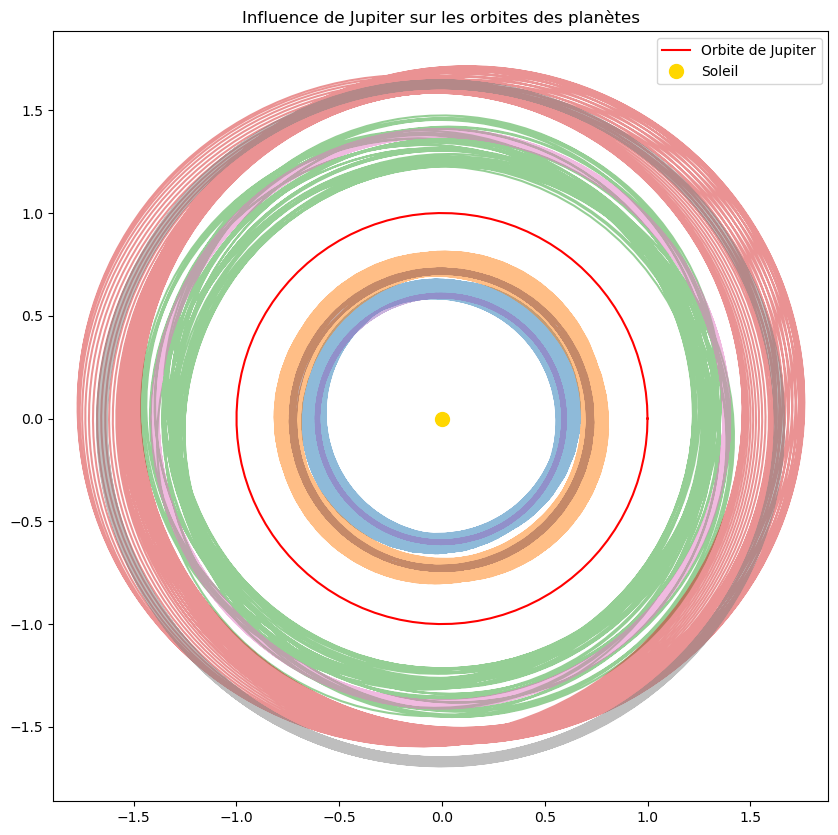

In [16]:
def jupiter_position(t):
    x1_J =  np.cos(t)
    x2_J =  np.sin(t)
    return x1_J, x2_J

def initial_value(t):
    r = t**(2/3)
    v = r**(-1/2)
    phi = np.random.random() * 2 * np.pi
    return [r * np.cos(phi), r * np.sin(phi), -v * np.sin(phi), v * np.cos(phi)]

periods = [1/2, 2/3, 3/2, 2, 0.467, 0.618, 1.618, 2.12]
planets = [initial_value(period) for period in periods]

# prépare l'image
plt.figure(figsize=(10, 10))
plt.axis('equal')
plt.title("Influence de Jupiter sur les orbites des planètes")

# dessine l'orbite de Jupiter
theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), 'r', label='Orbite de Jupiter')

# dessine le Soleil
plt.plot(0, 0, 'o', color='gold', markersize=10, label='Soleil')
plt.legend()

### ÉCRIS CI-DESSOUS ###

def f_Sun_and_Jupiter(t, y):

    x1, x2, v1, v2 = y

    r = np.sqrt(x1**2 + x2**2)

    a1_Soleil = -x1/r**3
    a2_Soleil =-x2/r**3
    
    x1_J, x2_J = jupiter_position(t)
    r_J = np.sqrt((x1_J - x1)**2 + (x2_J - x2)**2)

    mu = 1/1000

    a1_Jupiter = mu*(x1_J-x1)/r_J**3
    a2_Jupiter = mu*(x2_J-x2)/r_J**3

    a1 = a1_Soleil + a1_Jupiter
    a2 = a2_Soleil + a2_Jupiter

    return [v1, v2, a1, a2]

intervalle_temps = (0, 500)
temps_eval = np.linspace(0, 500, 5000)

for planete_initiale in planets:
    
    solution = solve_ivp(f_Sun_and_Jupiter, intervalle_temps, planete_initiale, t_eval=temps_eval, rtol=1e-9, atol=1e-9)

    plt.plot(solution.y[0], solution.y[1], alpha=0.5)

## Solutions exactes des EDO

Jusqu'à présent, nous résolvions les EDO numériquement. Pour la plupart d'entre elles, c'est tout ce que nous pouvons faire - leurs solutions ne peuvent pas être exprimées en termes de "fonctions élémentaires", comme log, sin, etc. Cependant, certaines EDO très importantes peuvent être résolues exactement, et nous utiliserons la bibliothèque python `sympy` pour le faire.

### Une introduction à sympy

Sympy est une bibliothèque pour les calculs symboliques. Elle peut résoudre des équations algébriques, calculer des dérivées et des intégrales, et bien d'autres choses. Nous commençons avec des variables sympy, appelées symboles, construisons des expressions à partir d'elles, et calculons avec ces expressions. Voici quelques exemples de ce qu'elle peut faire :


expr:


(alpha*sin(y) + x)**y


dérivée de expr par rapport à x:


y*(alpha*sin(y) + x)**y/(alpha*sin(y) + x)


dérivée seconde de expr par rapport à y:


(alpha*sin(y) + x)**y*(-alpha*(alpha*y*cos(y)**2/(alpha*sin(y) + x) + y*sin(y) - 2*cos(y))/(alpha*sin(y) + x) + (alpha*y*cos(y)/(alpha*sin(y) + x) + log(alpha*sin(y) + x))**2)


la même, mais simplifiée:


(-alpha*(alpha*y - alpha*sin(2*y) + x*y*sin(y) - 2*x*cos(y)) + (alpha*y*cos(y) + (alpha*sin(y) + x)*log(alpha*sin(y) + x))**2)*(alpha*sin(y) + x)**(y - 2)


la même, quand on substitue y = 0 et alpha = 1:


(x**2*log(x)**2 + 2*x)/x**2


on peut transformer une expression en fonction python si on veut l'utiliser pour des calculs numériques


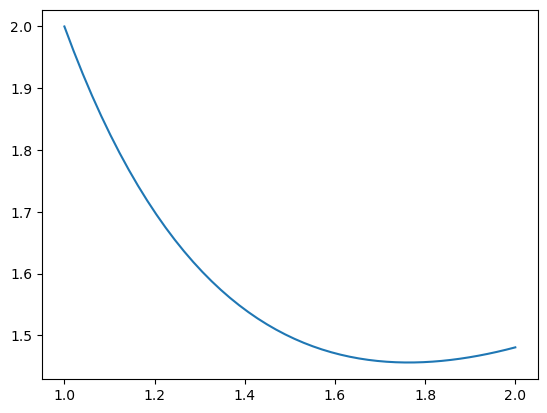

sympy peut aussi faire des calculs numériques avec une précision arbitraire:
h(2) =  1.4804530139182014246671025263266649717305529515945455868668641336236653822598345


In [68]:
### bases de sympy
### EXÉCUTE-MOI

import sympy as sp

# crée 3 symboles
x, y, alpha = sp.symbols('x, y, alpha')

expr = (x + alpha * sp.sin(y)) ** y

print('expr:')
# 'display' est une fonction définie dans Jupyter qui fonctionne bien avec les expressions sympy (mieux que print)
display(expr)
print()

print('dérivée de expr par rapport à x:')
display(expr.diff(x))
print()

print('dérivée seconde de expr par rapport à y:')
display(expr.diff(y, 2))
print()

print('la même, mais simplifiée:')
display(expr.diff(y, 2).simplify())
print()

print('la même, quand on substitue y = 0 et alpha = 1:')
display(expr.diff(y, 2).simplify().subs({y: 0, alpha:1}))
print()

print('on peut transformer une expression en fonction python si on veut l\'utiliser pour des calculs numériques')
# l'expression précédente à nouveau
h = expr.diff(y, 2).simplify().subs({y: 0, alpha:1})
# transforme-la en fonction python de x, compatible avec numpy
f = sp.lambdify(x, h, 'numpy')
# dessine son graphe
xx = np.linspace(1, 2)
plt.plot(xx, f(xx))
plt.show()

print('sympy peut aussi faire des calculs numériques avec une précision arbitraire:')
print('h(2) = ', h.subs(x, 2).n(80))


In [69]:
# un petit piège
### EXÉCUTE-MOI

# sympy est excellent pour convertir tous les types python en expressions symboliques, mais parfois il a besoin d'aide:
# 1/2 en python est un float, avec une précision limitée; pour obtenir un nombre rationnel, nous devons dire explicitement
# que 1 (ou 2) est un entier sympy; cela peut être fait avec sp.S(1) (S signifie "sympyfier")

display((1 + x)**(sp.S(1)/2))

print()
print('ceci n\'est probablement pas ce que tu veux (0.5 a une précision limitée):')
display((1 + x)**(1/2))

sqrt(x + 1)


ceci n'est probablement pas ce que tu veux (0.5 a une précision limitée):


(x + 1)**0.5

In [22]:
# quelques exemples d'analyse supplémentaires
### EXÉCUTE-MOI

x = sp.symbols('x')

# primitive
print('primitive de 1/(x^3-x):')
display(sp.integrate(1/(x**3 - x), x))
print()

# intégrale 
print('intégrale de x^6 exp(-x) de 0 à l\'infini:')
display( sp.integrate(x**6 * sp.exp(-x), (x, 0, sp.oo)))
print()

# sympy peut travailler avec des fonctions abstraites comme suit:
f = sp.Function('f')
g = sp.Function('g')
print('dérivée troisième de f(g(x)):')
# tu n'as pas besoin d'écrire 'display' si c'est la dernière expression dans la cellule
f(g(x)).diff(x, 3)

primitive de 1/(x^3-x):


-log(x) + log(x**2 - 1)/2


intégrale de x^6 exp(-x) de 0 à l'infini:


720


dérivée troisième de f(g(x)):


Derivative(f(g(x)), g(x))*Derivative(g(x), (x, 3)) + 3*Derivative(f(g(x)), (g(x), 2))*Derivative(g(x), x)*Derivative(g(x), (x, 2)) + Derivative(f(g(x)), (g(x), 3))*Derivative(g(x), x)**3

In [70]:
# comment sympy résout les équations algébriques
### EXÉCUTE-MOI


print('les quatre solutions complexes de x^2 + y^2 = 1 et y = x^2:')
print('(malheureusement imprimées de façon peu élégante)')
x, y = sp.symbols('x, y')
display(sp.solve([x**2 + y**2 - 1, y - x**2], x, y, dict=True))
print()


print('les deux solutions réelles des mêmes équations:')
x, y = sp.symbols('x, y', real=True)
display(sp.solve([x**2 + y**2 - 1, y - x**2], x, y, dict=True))
print()


print('résolution d\'une équation impliquant des matrices (un système linéaire)')
A = sp.Matrix([[x, 1], [y, x*x]])
print('A')
display(A)
v = sp.Matrix([3, x/y])
print('v')
display(v)
Ainv = A**-1
print('inverse de A')
display(Ainv)
print('résolution de A w = v en utilisant l\'inverse de A')
w = Ainv * v
print('w')
display(sp.simplify(w))


les quatre solutions complexes de x^2 + y^2 = 1 et y = x^2:
(malheureusement imprimées de façon peu élégante)


[{x: -sqrt(-1/2 + sqrt(5)/2), y: -1/2 + sqrt(5)/2},
 {x: sqrt(-1/2 + sqrt(5)/2), y: -1/2 + sqrt(5)/2},
 {x: -sqrt(-sqrt(5)/2 - 1/2), y: -sqrt(5)/2 - 1/2},
 {x: sqrt(-sqrt(5)/2 - 1/2), y: -sqrt(5)/2 - 1/2}]


les deux solutions réelles des mêmes équations:


[{x: -sqrt(-1/2 + sqrt(5)/2), y: -1/2 + sqrt(5)/2},
 {x: sqrt(-1/2 + sqrt(5)/2), y: -1/2 + sqrt(5)/2}]


résolution d'une équation impliquant des matrices (un système linéaire)
A


Matrix([
[x,    1],
[y, x**2]])

... (2 outputs left out)

inverse de A


Matrix([
[x**2/(x**3 - y), -1/(x**3 - y)],
[  -y/(x**3 - y),  x/(x**3 - y)]])

résolution de A w = v en utilisant l'inverse de A
w


Matrix([
[  x*(3*x*y - 1)/(y*(x**3 - y))],
[(x**2 - 3*y**2)/(y*(x**3 - y))]])

<div style="border: 1px solid gold; padding: 5px">


**Exercice :**

Le $n$-ième polynôme de Legendre $P_n(x)$ est défini comme 
$$P_n(x) = \frac1{n!}\Bigl(\frac{d^n}{dt^n}\frac1{\sqrt{1 - 2 x t + t^2}}\Bigr)\bigg|_{t=0}$$
C'est un polynôme de degré $n$. Une identité importante satisfaite par les $P_n$ est leur _orthogonalité_ :
$$\int_{-1}^1 P_n(x)P_m(x)\,dx =0 \quad\text{si}\quad m\neq n.$$

Calcule $P_6(x)$ et $P_{10}(x)$ et vérifie cette identité pour $n=6$ et $m=10$. Trace les graphes de ces deux polynômes (sur la même image) pour $-1\leq x\leq1$.
</div>

> Pour obtenir $n!$ dans sympy, utilise `sp.factorial(n)`.



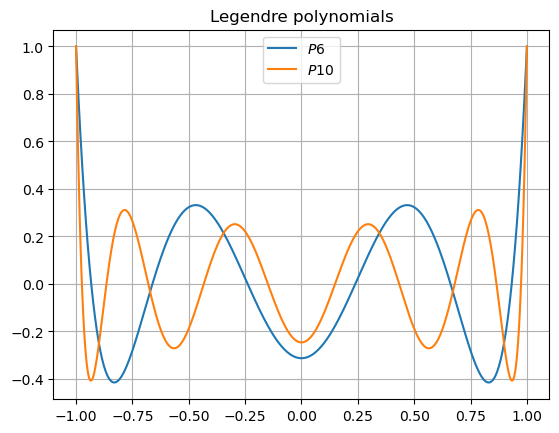

In [71]:
### ÉCRIS ICI
x, t = sp.symbols('x t')

def P(n):
    expr = 1 / sp.sqrt(1 - 2*x*t + t**2)
    derivee = sp.diff(expr, t, n)
    eval_zero = derivee.subs(t, 0)
    polynome = (1 / sp.factorial(n)) * eval_zero
    return sp.simplify(polynome)

P6 = P(6)
P10 = P(10)

f6 = sp.lambdify(x, P6, 'numpy')
f10 = sp.lambdify(x, P10, 'numpy')

xx = np.linspace(-1, 1, 500)

y6 = f6(xx) * np.ones_like(xx)
y10 = f10(xx) * np.ones_like(xx)

plt.plot(xx, y6, label='$P6$')
plt.plot(xx, y10, label='$P10$')
plt.title('Legendre polynomials')
plt.legend()
plt.grid()
plt.show()

### Résoudre des EDO avec sympy

Pour trouver toutes les solutions d'une EDO (si cela peut être fait "algébriquement"), nous utilisons la fonction `dsolve` de `sympy`. Nous devons d'abord créer la variable (généralement `t`), la fonction inconnue (généralement `y`) et écrire l'EDO sous la forme $eq = 0$, où `eq` est une expression sympy. Pour imposer une condition initiale, nous pouvons utiliser l'argument `ics` de `dsolve`. 

> `dsolve` est très intelligent, mais il ne peut pas résoudre toutes les EDO "algébriquement résolubles" sans aide. On peut lui donner des indices sur les méthodes qu'il devrait essayer, mais nous ne le ferons pas ici.

Exécute et lis la cellule ci-dessous pour voir comment ça marche.


In [72]:
# résoudre des EDO en utilisant sympy
### EXÉCUTE-MOI

t = sp.symbols('t')
y = sp.Function('y')

# y'(t) - y(t)
eq = y(t).diff(t) - y(t)

print("la solution générale de y' - y = 0 (C1 est une constante arbitraire) ")
gen_sol = sp.dsolve(eq)
display(gen_sol)

print("si on remplace C1 par 1:")
C1 = sp.symbols('C1')
display(gen_sol.subs(C1, 1))

print("la solution satisfaisant la condition initiale y(0) = 3:")
ini_sol = sp.dsolve(eq, ics={y(0):3})
display(ini_sol)

print("pour obtenir la solution à partir de l'égalité ci-dessus, utilise .rhs (right-hand side):")
display(ini_sol.rhs)

la solution générale de y' - y = 0 (C1 est une constante arbitraire) 


Eq(y(t), C1*exp(t))

si on remplace C1 par 1:


Eq(y(t), exp(t))

la solution satisfaisant la condition initiale y(0) = 3:


Eq(y(t), 3*exp(t))

pour obtenir la solution à partir de l'égalité ci-dessus, utilise .rhs (right-hand side):


3*exp(t)

Voici quelques exemples supplémentaires. La fonction `dsolve` peut traiter des EDO contenant des dérivées d'ordre supérieur et aussi des systèmes d'EDO. Pour ces derniers, `eq` doit être soit une liste d'équations, soit un vecteur (un objet `Matrix`).


In [73]:
# résoudre plus d'EDO en utilisant sympy
### EXÉCUTE-MOI

t = sp.symbols('t')
y = sp.Function('y')

# y''(t) + y(t) = 0
eq = y(t).diff(t, 2) + y(t)
print("solution générale de y''(t) + y(t) = 0")
display(sp.dsolve(eq))


x = sp.Function('x')
eq = [x(t).diff(t) - y(t), y(t).diff(t) + x(t)]
# sol est une liste avec 2 termes, un pour x et un pour y
sol = sp.dsolve(eq)
print("solution générale de x' - y = 0, y' + x = 0")
display(sol[0], sol[1])

v = sp.Matrix([x(t), y(t)])
A = sp.Matrix([[0, 1], [-1, 0]])
eq = v.diff(t) - A * v
sol = sp.dsolve(eq)
print("la même EDO, juste écrite avec des vecteurs et des matrices")
display(sol[0], sol[1])

eq = y(t).diff(t, 2) - t * y(t)
print("sympy peut résoudre y''(t) - t y(t) = 0, même si la solution utilise des fonctions spéciales (fonctions d'Airy)")
sol = sp.dsolve(eq)
display(sol)

print("et il peut calculer numériquement avec : voici y(1)")
sol.subs(t, 1).rhs.n(40)

solution générale de y''(t) + y(t) = 0


Eq(y(t), C1*sin(t) + C2*cos(t))

solution générale de x' - y = 0, y' + x = 0


Eq(x(t), C1*sin(t) + C2*cos(t))

Eq(y(t), C1*cos(t) - C2*sin(t))

la même EDO, juste écrite avec des vecteurs et des matrices


... (2 outputs left out)

sympy peut résoudre y''(t) - t y(t) = 0, même si la solution utilise des fonctions spéciales (fonctions d'Airy)


Eq(y(t), C1*airyai(t) + C2*airybi(t))

et il peut calculer numériquement avec : voici y(1)


0.1352924163128814155241474235154663061749*C1 + 1.207423594952871259436378817028286995385*C2

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Trouve la solution de l'EDO 
$$y'(t) = \frac{y(t)}{t+1} + \frac{t^5}{t+2}$$
avec la condition initiale $y(0) = 1$. Dessine le graphe de $y$ pour $0\leq t\leq 2$ (soit en utilisant `lambdify`, soit avec `sp.plot(expr, (t, 0, 2))`, où `expr` est la solution).
</div>

> Rappelle-toi que tu dois utiliser .rhs pour obtenir la solution comme une expression à partir d'une égalité $y(t) = \dots$


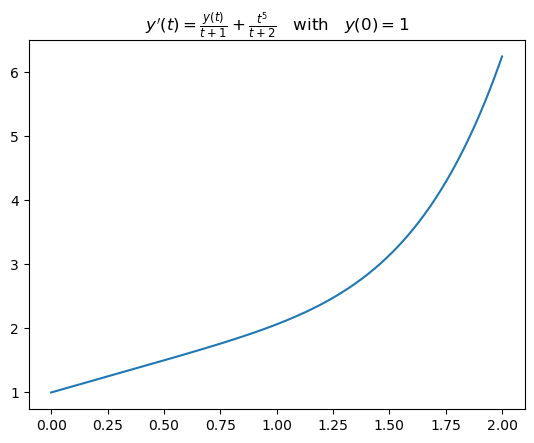

In [74]:
### ÉCRIS ICI

t = sp.symbols('t')
y = sp.Function('y')

eq = sp.Eq(y(t).diff(t), y(t)/(t + 1) + t**5/(t + 2))
sol = sp.dsolve(eq, ics={y(0): 1})
expr = sol.rhs

f = sp.lambdify(t, expr, 'numpy')

tt = np.linspace(0, 2, 500)
yy = f(tt)

plt.plot(tt, yy)
plt.title(r"$y'(t) = \frac{y(t)}{t+1} + \frac{t^5}{t+2}$   with   $y(0) = 1$")
plt.show()

## Pendule double : Combiner sympy avec scipy

La plupart des EDO ne peuvent pas être résolues explicitement et nous devons utiliser des outils numériques, comme la fonction `solve_ivp` de `scipy.integrate`.
Cependant, nous devons encore mettre notre EDO sous la forme
$$y' = f(t, y)$$
et implémenter la fonction $f(t, y)$ en python. Sympy peut être utile pour cela.

Essayons de calculer le mouvement d'un pendule double ($m_1$ et $m_2$ sont des masses, $\ell_1$ et $\ell_2$ sont des longueurs).

<img src="attachment:24ccdfd1-d6ca-41ec-aa8d-46ac6e82f219.png" width="600">


Écrire explicitement les équations différentielles satisfaites par les angles $q_1$ et $q_2$ est assez laborieux. Une approche standard utilisée en mécanique consiste à calculer d'abord l'énergie du pendule (composée de l'énergie potentielle et de l'énergie cinétique). Pour la rendre vraiment utile, l'énergie est exprimée en termes de $q_1, q_2$, et des "moments" (ou "impulsions") correspondants $p_1, p_2$. L'explication de cela va un peu au-delà de la physique du collège. Le calcul (utilisant sympy) est dans la cellule ci-dessous. L'énergie est notée $H$ et est appelée (d'après le découvreur de cette méthode, qui fonctionne pour n'importe quel système mécanique, pas seulement un pendule) _Hamiltonien_.

> (Ignore cette explication si elle ne t'intéresse pas.)
>
> Que sont ces "moments"? L'énergie cinétique du pendule (en supposant que ses bras ont des masses négligeables) est 
> $K = \frac12 m_1 v_1^2 + \frac12 m_2 v_2^2$, où $v_1$ est la vitesse de la masse $m_1$ et $v_2$ celle de la masse $m_2$. Nous pouvons calculer $v_1$ et $v_2$ en termes de $dq_1/dt$ et $dq_2/dt$, ce qui nous donnera (en notant par $q$ le vecteur 2D avec les composantes $q_1$ et $q_2$)
> $$ K =\frac12 \frac{dq}{dt}^T G(q)\; \frac{dq}{dt}$$
> pour une matrice symétrique 2x2 $G(q)$ appropriée (dépendante de $q$). Le vecteur des moments est alors
> $$p = G(q)\; \frac{dq}{dt}$$
> et l'énergie cinétique exprimée en termes de $p$ et $q$ est
> $$K = \frac12 p^T\, G(q)^{-1}\, p$$

Exécute la cellule ci-dessous. Essaie de lire le code (et ne t'inquiète pas si tu te perds - contente-toi d'avoir une idée du calcul).







In [75]:
# calculer le Hamiltonien
### EXÉCUTE-MOI


# les constantes
l1, l2, m1, m2, g = sp.symbols('l1, l2, m1, m2, g')

# les variables
q1, q2, p1, p2 = sp.symbols('q1, q2, p1, p2')

# (x1, x2) est la position de la masse m1
x1 = l1 * sp.sin(q1)
x2 = -l1 * sp.cos(q1)

# (X1, X2) est la position de la masse m2
X1 = x1 + l2 * sp.sin(q2)
X2 = x2 - l2 * sp.cos(q2)

# V est l'énergie potentielle
V = m1 * g * x2 + m2 * g * X2

# variables combinées en vecteurs 2D
q = sp.Matrix([q1, q2])
p = sp.Matrix([p1, p2])

# les positions de m1 et m2 combinées en un vecteur x de dimension 4
x = sp.Matrix([x1, x2, X1, X2])

# la matrice jacobienne de q -> x (= matrice 4×2 avec éléments ∂x/∂q)
Jac = x.jacobian(q)

# la matrice 4×4 diagonale des masses
M = sp.diag(m1, m1, m2, m2)

# Jac.T est la transposée de Jac
G = Jac.T * M * Jac
G = sp.simplify(G)

# K est l'énergie cinétique exprimée en termes de moments
# (sans [0], K serait une matrice 1x1; [0] donne son élément)
K = (p.T * G**(-1) * p)[0] / 2
K = sp.simplify(K)

# H est le Hamiltonien = énergie totale
H = V + K

print('Le Hamiltonien avec toutes les constantes:')
display(H)

# set all the constants (lengths, masses, and g) to particular numbers
values = {m1:3, m2:1, l1:3, l2:2, g:9.80665}
H = H.subs(values)
print('H après avoir fixé  les constantes:', values)
display(H)

Le Hamiltonien avec toutes les constantes:


-g*l1*m1*cos(q1) + g*m2*(-l1*cos(q1) - l2*cos(q2)) + (l1**2*m1*p2**2 + l1**2*m2*p2**2 - 2*l1*l2*m2*p1*p2*cos(q1 - q2) + l2**2*m2*p1**2)/(2*l1**2*l2**2*m2*(m1 - m2*cos(q1 - q2)**2 + m2))

H après avoir fixé  les constantes: {m1: 3, m2: 1, l1: 3, l2: 2, g: 9.80665}


-117.6798*cos(q1) - 19.6133*cos(q2) + (4*p1**2 - 12*p1*p2*cos(q1 - q2) + 36*p2**2)/(72*(4 - cos(q1 - q2)**2))

Une fois que nous avons la fonction $H(q_1, q_2, p_1, p_2)$, l'EDO (appelée _équations de Hamilton_) pour le mouvement du pendule est
$$\frac{dq_i}{dt} = \frac{\partial H}{\partial p_i}\qquad(i=1,2)$$
$$\frac{dp_i}{dt} = - \frac{\partial H}{\partial q_i}\qquad(i=1,2)$$
(la notation $\frac{\partial H}{\partial p_i}$ signifie la dérivée de $H$ par rapport à $p_i$).


<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

 - Calcule la liste `RHS` contenant les 4 membres de droite $\frac{\partial H}{\partial p_i}$, $-\frac{\partial H}{\partial q_i}$ des équations ci-dessus (`H` a été calculé dans la cellule précédente, alors calcule simplement ses dérivées).
 - Transforme `RHS` (une liste d'expressions sympy) en une fonction `f(t, y)` qui peut être donnée à `solve_ivp`. La fonction `f` s'attendra à ce que `y` soit une liste (ou toute autre séquence) de 4 nombres et `t` un nombre ; elle renverra une liste de 4 nombres. Fais-le avec
```python
# nous avons besoin de la variable t qui n'a pas été utilisée jusqu'à présent
t = sp.symbols('t')

# une syntaxe plus flexible pour lambdify:
# elle dit que le 1er argument de f est un nombre et le 2e une liste de 4 nombres
# `RHS` est une liste de 4 expressions, donc f renverra une liste de 4 nombres
f = sp.lambdify([t, [q1, q2, p1, p2]], RHS)
```
 - Utilise `solve_ivp` pour résoudre l'EDO avec la condition initiale `q1=3`, `q2=p1=p2=0` (c.-à-d. `y0=[3,0,0,0]`), pour l'intervalle de temps $[0, 50]$. Trace la trajectoire suivie par l'extrémité du pendule (c.-à-d. par la masse $m_2$) - **n'oublie pas que $\ell_1=3$ et $\ell_2=2$ en préparant l'image!**
</div>

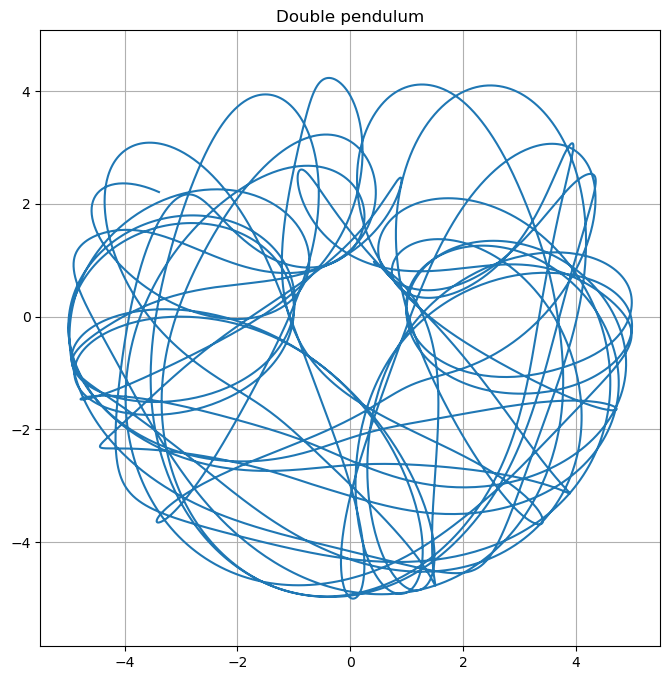

In [76]:
### ÉCRIS ICI
RHS = [
    sp.diff(H, p1),
    sp.diff(H, p2),
    -sp.diff(H, q1),
    -sp.diff(H, q2)
]

t = sp.symbols('t')
f = sp.lambdify([t, [q1, q2, p1, p2]], RHS)

t_span = (0, 50)
y0 = [3, 0, 0, 0]
t_eval = np.linspace(t_span[0], t_span[1], 10000)

sol = solve_ivp(f, t_span, y0, t_eval=t_eval)

q1_sol = sol.y[0]
q2_sol = sol.y[1]

X1_sol = 3 * np.sin(q1_sol) + 2 * np.sin(q2_sol)
X2_sol = -3 * np.cos(q1_sol) - 2 * np.cos(q2_sol)

plt.figure(figsize=(8, 8))
plt.plot(X1_sol, X2_sol, linewidth=1.5)
plt.title('Double pendulum')
plt.grid()
plt.axis('equal') 
plt.show()

Voici la solution sous forme d'animation (pour $0\leq t\leq100$). Si tu veux apprendre à créer des animations avec matplotlib, [regarde ici](https://matplotlib.org/stable/users/explain/animations/animations.html). Execute la cellule dessous (le code utilise la fonction `f` que tu as crée dans la cellule précédente).

>  l'option `t_eval=np.linspace(0, 100, 1000)` utilisée dans `solve_ivp` détermine les valeurs de $t$ (sans cette option, `solve_ivp` choisit les valeurs de $t$ automatiquement)



In [77]:
### EXECUTE-MOI

from matplotlib.animation import ArtistAnimation
from IPython.display import HTML

# résoudre l'EDO
y0 = [3,0,0,0]
sol = solve_ivp(f, [0, 100], y0, t_eval=np.linspace(0, 100, 1000), atol=1e-10, rtol=1e-10)
q1n, q2n, p1n, p2n = sol.y

# calculer les coordonnées des masses ((x1n,x2n) pour m1 et (X1n, X2n) pour m2)
x1n, x2n = 3 * np.sin(q1n), -3 * np.cos(q1n)
X1n, X2n = x1n + 2 * np.sin(q2n), x2n - 2 * np.cos(q2n)

# préparer la figure (une petite pour que ce soit rapide)
fig = plt.figure(figsize=(2.5,2.5))
plt.xlim(-5.1, 5.1)
plt.ylim(-5.1, 5.1)
plt.axis('off')

# créer les dessins du pendule (images de l'animation)
pics = []
for i in range(1000):
    pics.append(plt.plot([0, x1n[i], X1n[i]], [0, x2n[i], X2n[i]], '.-', color='black'))
    
# créer l'animation
anim = ArtistAnimation(fig=fig, artists=pics, interval=50)

# pour sauvegarder dans différents formats (la 1ère option nécessite ffmpeg)
# anim.save('double_pendulum.mp4', writer='ffmpeg', fps=20, dpi=100)
# anim.save('double_pendulum.gif', writer='pillow', fps=20)

# Afficher l'animation dans Jupyter
plt.close()
HTML(anim.to_jshtml())